# Benchmarking my Linear Regression (from scratch) vs scikit-learn

A benchmark answers three simple questions:

1. **Is it correct?** Does my code compute the right maths?
2. **Is it accurate?** Does it predict as well as scikit-learn on real data?
3. **Is it fast?** How long does it take to train and to predict?

**Rules for a fair comparison:**
* Every model gets exactly the same data splits.
* Every model scales features the same way (z-score), fitted on the training data only.
* Run several times and report the average and the spread, never a single number.
* Use a fixed random seed so the results can be reproduced.

Run the cells from top to bottom. The figures are saved in the `figures/` folder, so you can put them in your README.

## 0. Setup

In [1]:
import sys
import subprocess

print("Python executable:", sys.executable)

subprocess.run([
    sys.executable, "-m", "pip", "show",
    "scikit-learn", "numpy", "scipy", "Cython"
])

Python executable: C:\Dream\Learnaholic\AI from First Principles\.venv\Scripts\python.exe


CompletedProcess(args=['C:\\Dream\\Learnaholic\\AI from First Principles\\.venv\\Scripts\\python.exe', '-m', 'pip', 'show', 'scikit-learn', 'numpy', 'scipy', 'Cython'], returncode=0)

In [2]:
import sys
import time
import timeit
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import fetch_california_housing, load_diabetes, make_regression
from sklearn.linear_model import LinearRegression as SkLinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Yours (default)": "#E69F00", "Yours (tuned)": "#D55E00", "sklearn": "#0072B2"}

### Import your model

Your file uses relative imports (`from ..loss.mse import MSE`), so it must be imported **as part of your package**. Python needs to know the folder that *contains* your package. With this layout, the cell below works after you change `your_package` to your package's real name:

```
my_project/
├── your_package/              ← loss/, optimizers/, regularizers/, feature_scaling/, models/
└── notebooks/
    └── benchmark_linear_regression.ipynb
```

In [7]:
from pathlib import Path
import sys

SRC_ROOT = Path(
    r"C:\Dream\Learnaholic\AI from First Principles\libcode\src"
).resolve()

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from ml.models.linear_regression import LinearRegression as MyLR
print("Imported:", MyLR)

Imported: <class 'ml.models.linear_regression.LinearRegression'>


### The contenders

* **Yours (default):** your class exactly as it is (learning rate 0.001, 10,000 iterations).
* **Yours (tuned):** the same code with a bigger learning rate and a stricter stopping rule. Comparing the two shows whether a difference comes from your *code* or from your *default settings*.
* **sklearn:** `StandardScaler` + `LinearRegression`. It solves the problem exactly, without gradient descent, so it is our "correct answer".

In [8]:
def make_models():
    """Return fresh (untrained) models. Called again for every fold, so nothing leaks between runs."""
    return {
        "Yours (default)": MyLR(),
        "Yours (tuned)": MyLR(learning_rate=0.1, n_iter=20_000, convergence_limit=1e-10),
        "sklearn": make_pipeline(StandardScaler(), SkLinearRegression()),
    }

### Datasets

* **California Housing** (20,640 rows × 8 features) is the standard real-world regression dataset in scikit-learn. It is downloaded once, then cached.
* **Diabetes** (442 rows × 10 features) is small, with strongly correlated features.
* **Synthetic** data is generated by `make_regression`, so we know the data really is linear.

In [9]:
datasets = {}
try:
    X, y = fetch_california_housing(return_X_y=True)
    datasets["California Housing"] = (X, y)
except Exception as error:
    print("Could not download California Housing (are you offline?):", error)

X, y = load_diabetes(return_X_y=True)
datasets["Diabetes"] = (X, y)

X, y = make_regression(n_samples=5_000, n_features=20, noise=10.0, random_state=SEED)
datasets["Synthetic"] = (X, y)

for name, (X, y) in datasets.items():
    print(f"{name:<20} {X.shape[0]:>6} rows × {X.shape[1]} features")

# the dataset we use for the single-split experiments below
MAIN = "California Housing" if "California Housing" in datasets else "Diabetes"
print("\nMain dataset:", MAIN)

California Housing    20640 rows × 8 features
Diabetes                442 rows × 10 features
Synthetic              5000 rows × 20 features

Main dataset: California Housing


## 1. Correctness

### 1.1 Gradient check

Gradient descent only works if the gradients are right. We can check them **without any library**: nudge one weight up by a tiny `eps`, nudge it down, and see how much the cost changes. That gives a numerical gradient:

$$\frac{\partial J}{\partial w_i} \approx \frac{J(w_i + \varepsilon) - J(w_i - \varepsilon)}{2\varepsilon}$$

If your analytic gradient (`_gradients()`) is correct, the two agree almost perfectly. A relative error below about `1e-7` is a pass. We use `lambda_w > 0` so the L2 gradient is tested too.

In [10]:
X, y = make_regression(n_samples=100, n_features=5, noise=1.0, random_state=SEED)
model = MyLR(lambda_w=0.5, lambda_b=0.2, n_iter=1).fit(X, y)   # 1 iteration: just sets up model.X, model.y, ...

rng = np.random.default_rng(SEED)
model.weights = rng.normal(size=5)    # test the gradient at a random point
model.bias = 0.3

# analytic gradient (your code)
dw, db = model._gradients()
analytic = np.append(dw, db)

# numerical gradient (finite differences of your cost function)
eps = 1e-6
numeric = []
for i in range(6):                    # 5 weights + 1 bias
    params = np.append(model.weights, model.bias)
    costs = []
    for step in (+eps, -eps):
        p = params.copy()
        p[i] += step
        model.weights, model.bias = p[:-1], p[-1]
        costs.append(model._cost_function())
    model.weights, model.bias = params[:-1], params[-1]   # restore
    numeric.append((costs[0] - costs[1]) / (2 * eps))
numeric = np.array(numeric)

grad_error = np.linalg.norm(analytic - numeric) / (np.linalg.norm(analytic) + np.linalg.norm(numeric))
print(f"Relative error between analytic and numerical gradient: {grad_error:.2e}")
print("✅ PASS: your gradients are correct" if grad_error < 1e-7 else "❌ FAIL: check _gradients() / your loss classes")

Relative error between analytic and numerical gradient: 8.85e-09
✅ PASS: your gradients are correct


### 1.2 Do we learn the same weights as scikit-learn?

On clean synthetic data, both implementations should end up with the same weights and make the same predictions. Both work on z-scored features, so the weights can be compared directly.

,model,iterations used,max |weight difference|,max |prediction difference|,test R² (yours),test R² (sklearn)
0,Yours (default),5380,0.002883,0.015788,0.995849,0.995849
1,Yours (tuned),79,0.000007,0.000046,0.995849,0.995849


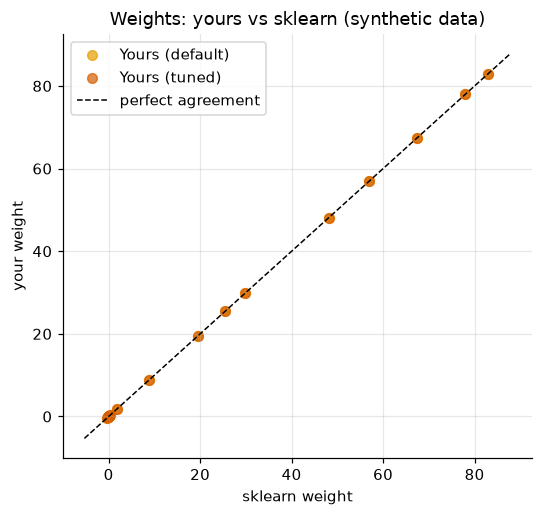

In [11]:
X, y = datasets["Synthetic"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

sk = make_pipeline(StandardScaler(), SkLinearRegression()).fit(X_train, y_train)
sk_weights = sk[-1].coef_          # the LinearRegression step inside the pipeline

rows = []
my_weights = {}
for name in ["Yours (default)", "Yours (tuned)"]:
    mine = make_models()[name].fit(X_train, y_train)
    my_weights[name] = mine.weights
    rows.append({
        "model": name,
        "iterations used": len(mine.history),
        "max |weight difference|": np.max(np.abs(mine.weights - sk_weights)),
        "max |prediction difference|": np.max(np.abs(mine.predict(X_test) - sk.predict(X_test))),
        "test R² (yours)": r2_score(y_test, mine.predict(X_test)),
        "test R² (sklearn)": r2_score(y_test, sk.predict(X_test)),
    })
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, w in my_weights.items():
    ax.scatter(sk_weights, w, s=40, alpha=0.7, color=COLORS[name], label=name)
lims = [sk_weights.min() - 5, sk_weights.max() + 5]
ax.plot(lims, lims, "k--", lw=1, label="perfect agreement")
ax.set(xlabel="sklearn weight", ylabel="your weight", title="Weights: yours vs sklearn (synthetic data)")
ax.legend()
fig.savefig(FIG_DIR / "1_weights_vs_sklearn.png", bbox_inches="tight")
plt.show()

## 2. Convergence

Gradient descent is iterative, so we look at the **cost after every iteration**. Your model stores it in `model.history`.

* A good learning rate gives a curve that drops quickly and then flattens.
* A learning rate that is too small gives a curve that is still dropping when training stops.
* A learning rate that is too big gives a curve that shoots up (divergence).

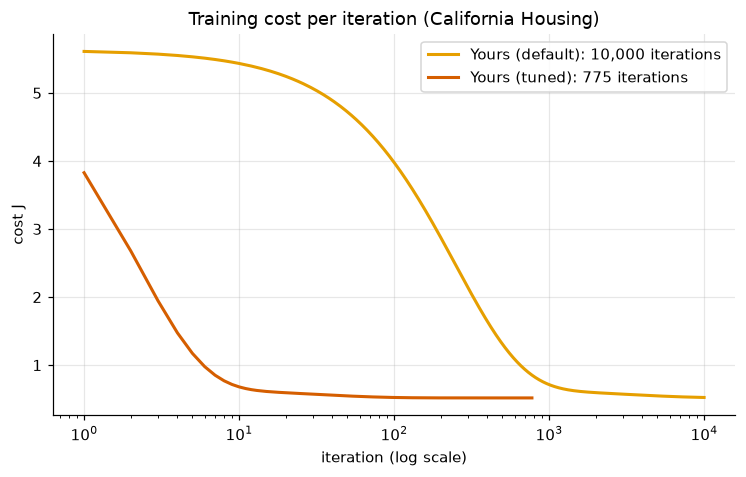

In [12]:
X, y = datasets[MAIN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ["Yours (default)", "Yours (tuned)"]:
    model = make_models()[name].fit(X_train, y_train)
    ax.plot(np.arange(1, len(model.history) + 1), model.history, color=COLORS[name], lw=2,
            label=f"{name}: {len(model.history):,} iterations")
ax.set(xscale="log", xlabel="iteration (log scale)", ylabel="cost J",
       title=f"Training cost per iteration ({MAIN})")
ax.legend()
fig.savefig(FIG_DIR / "2_convergence.png", bbox_inches="tight")
plt.show()

C:\Dream\Learnaholic\AI from First Principles\.venv\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


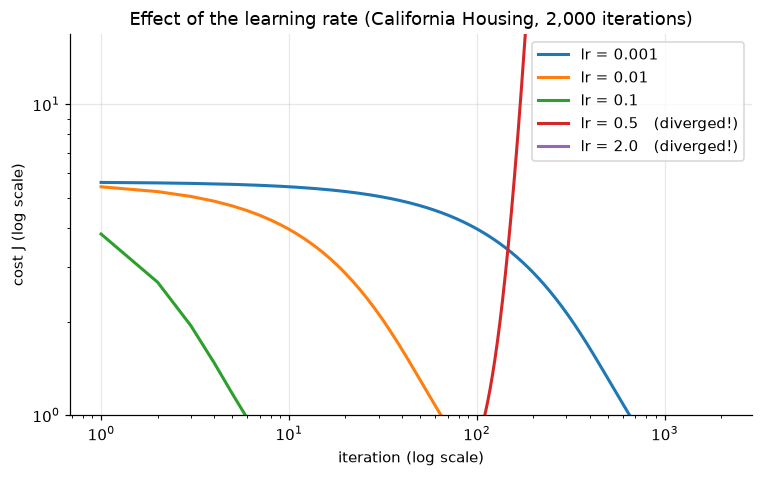

In [13]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 2.0]

fig, ax = plt.subplots(figsize=(8, 4.5))
first_cost = None
for lr in learning_rates:
    with np.errstate(all="ignore"):          # hide overflow warnings when it diverges
        model = MyLR(learning_rate=lr, n_iter=2_000, convergence_limit=0).fit(X_train, y_train)
    history = np.array(model.history, dtype=float)
    first_cost = history[0] if first_cost is None else first_cost
    diverged = (not np.isfinite(history[-1])) or history[-1] > history[0]
    ax.plot(np.arange(1, len(history) + 1), history, lw=2,
            label=f"lr = {lr}" + ("   (diverged!)" if diverged else ""))
ax.set(xscale="log", yscale="log", ylim=(None, first_cost * 3),
       xlabel="iteration (log scale)", ylabel="cost J (log scale)",
       title=f"Effect of the learning rate ({MAIN}, 2,000 iterations)")
ax.legend()
fig.savefig(FIG_DIR / "3_learning_rates.png", bbox_inches="tight")
plt.show()

## 3. Accuracy with 5-fold cross-validation

One train/test split can be lucky or unlucky. **K-fold cross-validation** splits the data into 5 parts. Each part is used once as the test set, while the model trains on the other 4. We get 5 scores per model and report their mean and standard deviation.

All models see **the same 5 splits**, which keeps the comparison fair.

Metrics:
* **R²** (higher is better, 1.0 is perfect): how much of the variation in y the model explains.
* **RMSE** (lower is better): the typical error, in the same units as y.
* **MAE** (lower is better): the average absolute error.

In [14]:
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for dataset_name, (X, y) in datasets.items():
    for fold, (train_idx, test_idx) in enumerate(kfold.split(X)):
        for model_name, model in make_models().items():
            start = time.perf_counter()
            model.fit(X[train_idx], y[train_idx])
            fit_time = time.perf_counter() - start

            y_pred = model.predict(X[test_idx])
            y_true = y[test_idx]
            rows.append({
                "dataset": dataset_name, "model": model_name, "fold": fold,
                "R2": r2_score(y_true, y_pred),
                "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
                "MAE": mean_absolute_error(y_true, y_pred),
                "fit_time_s": fit_time,
            })
    print("done:", dataset_name)

results = pd.DataFrame(rows)
results.to_csv("cv_results.csv", index=False)

summary = results.groupby(["dataset", "model"]).agg(
    R2_mean=("R2", "mean"), R2_std=("R2", "std"),
    RMSE_mean=("RMSE", "mean"), MAE_mean=("MAE", "mean"),
    fit_time_s=("fit_time_s", "mean"),
).round(4)
display(summary)

done: California Housing
done: Diabetes
done: Synthetic


R2_mean  R2_std  RMSE_mean  MAE_mean  \
dataset            model                                                   
California Housing Yours (default)   0.5969  0.0169     0.7324    0.5338   
                   Yours (tuned)     0.6014  0.0190     0.7283    0.5317   
                   sklearn           0.6014  0.0190     0.7283    0.5317   
Diabetes           Yours (default)   0.4785  0.0907    54.8728   44.2757   
                   Yours (tuned)     0.4785  0.0950    54.8489   44.2697   
                   sklearn           0.4785  0.0950    54.8489   44.2697   
Synthetic          Yours (default)   0.9960  0.0003    10.0248    7.9976   
                   Yours (tuned)     0.9960  0.0003    10.0248    7.9976   
                   sklearn           0.9960  0.0003    10.0248    7.9976   

                                    fit_time_s  
dataset            model                        
California Housing Yours (default)      1.9436  
                   Yours (tuned)        0.1521  
                   sklearn              0.0071  
Diabetes           Yours (default)      0.4564  
                   Yours (tuned)        0.2712  
                   sklearn              0.0015  
Synthetic          Yours (default)      0.4867  
                   Yours (tuned)        0.0079  
                   sklearn              0.0045

Because every model used the same folds, we can compare them **fold by fold**. The table shows the largest difference in R² between your model and sklearn across the 5 folds. A value like `1e-08` means the results are effectively identical.

,max |ΔR²| Yours (default) vs sklearn,max |ΔR²| Yours (tuned) vs sklearn
dataset,,
California Housing,7.455890e-03,8.180065e-06
Diabetes,8.377908e-03,4.539207e-07
Synthetic,3.170627e-07,6.092872e-10


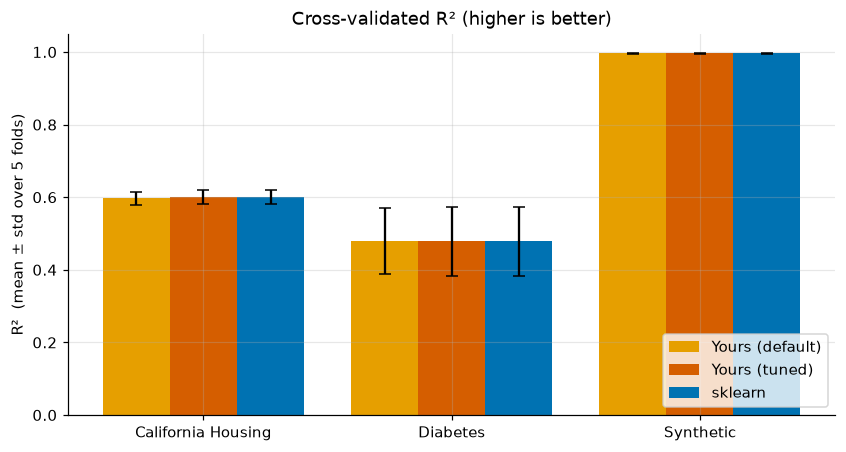

In [15]:
r2_per_fold = results.pivot_table(index=["dataset", "fold"], columns="model", values="R2")
r2_gap = pd.DataFrame({
    name: (r2_per_fold[name] - r2_per_fold["sklearn"]).abs().groupby(level="dataset").max()
    for name in ["Yours (default)", "Yours (tuned)"]
})
r2_gap.columns = [f"max |ΔR²| {name} vs sklearn" for name in r2_gap.columns]
display(r2_gap)

means = results.pivot_table(index="dataset", columns="model", values="R2", aggfunc="mean")
stds = results.pivot_table(index="dataset", columns="model", values="R2", aggfunc="std")

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(means))
width = 0.27
for i, name in enumerate(COLORS):
    ax.bar(x + (i - 1) * width, means[name], width, yerr=stds[name], capsize=4,
           color=COLORS[name], label=name)
ax.set_xticks(x)
ax.set_xticklabels(means.index)
ax.set(ylim=(0, 1.05), ylabel="R²  (mean ± std over 5 folds)", title="Cross-validated R² (higher is better)")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "4_cv_r2.png", bbox_inches="tight")
plt.show()

### 3.2 Prediction plots

* **Left:** your predictions vs sklearn's. If the implementations agree, every point lies on the dashed diagonal.
* **Right:** true values vs predictions. This shows how good *linear regression itself* is on this dataset, whichever implementation you use.

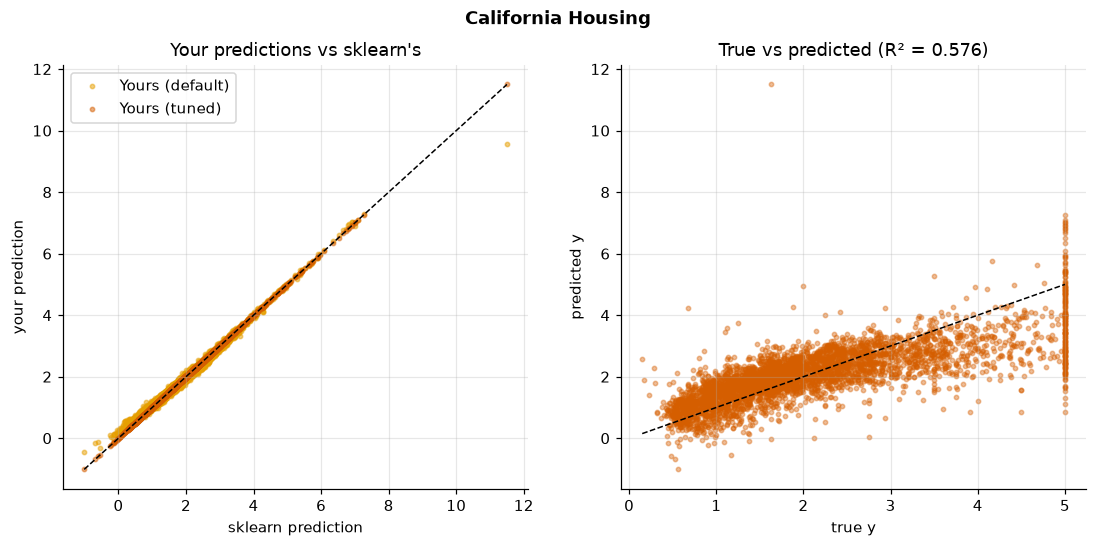

In [16]:
X, y = datasets[MAIN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
fitted = {name: model.fit(X_train, y_train) for name, model in make_models().items()}
pred = {name: model.predict(X_test) for name, model in fitted.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in ["Yours (default)", "Yours (tuned)"]:
    axes[0].scatter(pred["sklearn"], pred[name], s=8, alpha=0.5, color=COLORS[name], label=name)
lims = [pred["sklearn"].min(), pred["sklearn"].max()]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set(xlabel="sklearn prediction", ylabel="your prediction", title="Your predictions vs sklearn's")
axes[0].legend()

axes[1].scatter(y_test, pred["Yours (tuned)"], s=8, alpha=0.4, color=COLORS["Yours (tuned)"])
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set(xlabel="true y", ylabel="predicted y",
            title=f"True vs predicted (R² = {r2_score(y_test, pred['Yours (tuned)']):.3f})")
fig.suptitle(MAIN, fontweight="bold")
fig.savefig(FIG_DIR / "5_predictions.png", bbox_inches="tight")
plt.show()

## 4. Regularization: your L2 vs sklearn's Ridge

sklearn's `Ridge(alpha)` minimises  $\lVert Xw + b - y\rVert^2 + \alpha\lVert w\rVert^2$.

Your model minimises  `MSE + (lambda_w / m) · L2(w)`, and its scaling depends on how you wrote `MSE` and `L2` (for example 1/(2m) or 1/m, and ½‖w‖² or ‖w‖²). The next cell **measures** those scales from your own classes and works out the matching `lambda_w` for each `alpha`. Then we plot the **regularization path**: how each weight shrinks as alpha grows. The lines are sklearn and the circles are yours, so they should sit on top of each other.

In [17]:
probe = MyLR()
r = np.array([1.0, 2.0, 3.0])
loss_scale = probe.loss.cost(r, np.zeros(3)) * len(r) / np.sum(r ** 2)    # 0.5 if MSE = 1/(2m)·Σ(error²)
w = np.array([1.0, 2.0, 3.0])
reg_scale = probe.regularization.cost(w) / np.sum(w ** 2)                  # 0.5 if L2 = ½·‖w‖²
LAMBDA_PER_ALPHA = loss_scale / reg_scale
print(f"Your MSE scale = {loss_scale}, your L2 scale = {reg_scale}")
print(f"→ sklearn Ridge(alpha) matches your model with lambda_w = {LAMBDA_PER_ALPHA} × alpha")

Your MSE scale = 1.0, your L2 scale = 1.0
→ sklearn Ridge(alpha) matches your model with lambda_w = 1.0 × alpha


Largest weight difference along the whole path: 1.30e-03


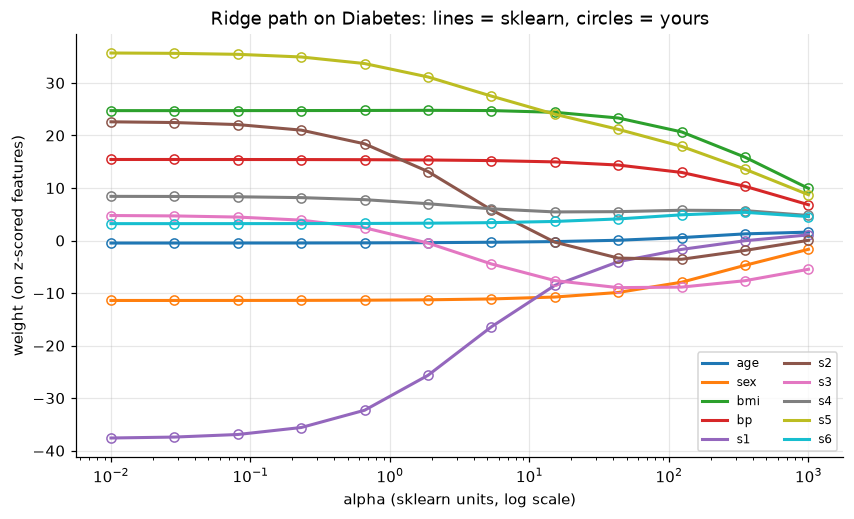

In [18]:
X, y = datasets["Diabetes"]
feature_names = load_diabetes().feature_names
alphas = np.logspace(-2, 3, 12)

sk_path, my_path = [], []
for alpha in alphas:
    sk_ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X, y)
    mine = MyLR(lambda_w=alpha * LAMBDA_PER_ALPHA, learning_rate=0.1,
                n_iter=20_000, convergence_limit=1e-10).fit(X, y)
    sk_path.append(sk_ridge[-1].coef_)
    my_path.append(mine.weights)
sk_path, my_path = np.array(sk_path), np.array(my_path)

print(f"Largest weight difference along the whole path: {np.max(np.abs(sk_path - my_path)):.2e}")

fig, ax = plt.subplots(figsize=(9, 5))
for j, name in enumerate(feature_names):
    color = plt.cm.tab10(j)
    ax.plot(alphas, sk_path[:, j], color=color, lw=2, label=name)
    ax.plot(alphas, my_path[:, j], "o", color=color, mfc="none")
ax.set(xscale="log", xlabel="alpha (sklearn units, log scale)", ylabel="weight (on z-scored features)",
       title="Ridge path on Diabetes: lines = sklearn, circles = yours")
ax.legend(ncol=2, fontsize=8)
fig.savefig(FIG_DIR / "6_ridge_path.png", bbox_inches="tight")
plt.show()

## 5. Speed

How to time code properly:
* Run once first as a **warm-up** (the first run is often slower).
* Repeat the measurement several times and take the **median**, which ignores unlucky slow runs.
* Use `time.perf_counter()` or `timeit`, not `time.time()`.

**Expect sklearn to train much faster.** It solves least squares directly in one step, while gradient descent needs thousands of iterations. That comes from the algorithm, not from a mistake in your code. Prediction is a single matrix multiplication for both, so that part is a fairer race.

,fit (ms),predict test set (ms),predict 1 row (µs),fit: × slower than sklearn
model,,,,
Yours (default),1864.557,0.081,5.430,287.275
Yours (tuned),143.680,0.085,5.354,22.137
sklearn,6.490,0.363,254.261,1.000


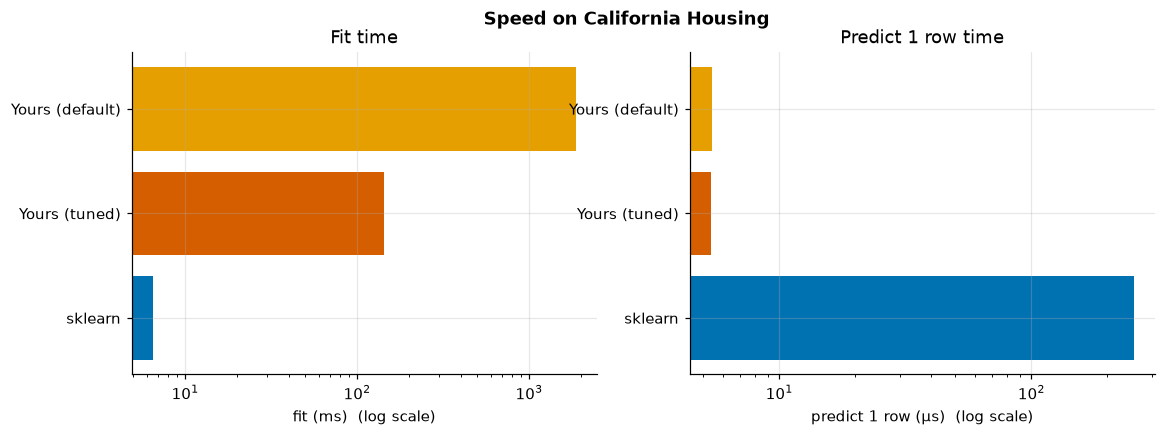

In [19]:
def median_time(fn, repeats=5, number=1):
    """Median seconds per call over `repeats` measurements of `number` calls each."""
    fn()                                                    # warm-up
    times = timeit.repeat(fn, repeat=repeats, number=number)
    return np.median(times) / number

X, y = datasets[MAIN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
one_row = X_test[:1]

rows = []
for name, model in make_models().items():
    fit_s = median_time(lambda: model.fit(X_train, y_train))
    predict_s = median_time(lambda: model.predict(X_test), number=100)
    one_row_s = median_time(lambda: model.predict(one_row), number=1_000)
    rows.append({"model": name, "fit (ms)": fit_s * 1e3, "predict test set (ms)": predict_s * 1e3,
                 "predict 1 row (µs)": one_row_s * 1e6})
speed = pd.DataFrame(rows).set_index("model")
speed["fit: × slower than sklearn"] = speed["fit (ms)"] / speed.loc["sklearn", "fit (ms)"]
display(speed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, column in zip(axes, ["fit (ms)", "predict 1 row (µs)"]):
    ax.barh(speed.index, speed[column], color=[COLORS[n] for n in speed.index])
    ax.set(xscale="log", xlabel=column + "  (log scale)", title=column.split(" (")[0].capitalize() + " time")
    ax.invert_yaxis()
fig.suptitle(f"Speed on {MAIN}", fontweight="bold")
fig.savefig(FIG_DIR / "7_speed.png", bbox_inches="tight")
plt.show()

### 5.2 How does training time grow with the dataset size?

We train on bigger and bigger synthetic datasets. Your model runs a fixed 500 iterations, so we measure the cost per iteration. On a log-log plot, a straight line with slope 1 means "twice the data takes twice the time" (linear scaling).

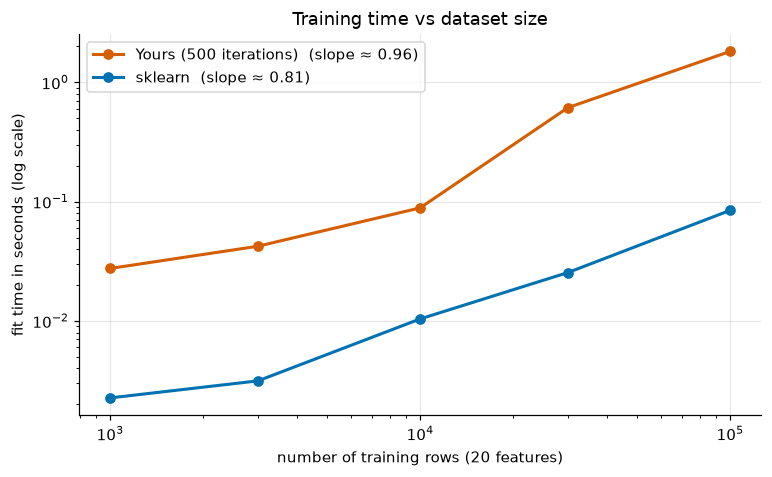

In [20]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000]
fit_times = {"Yours (500 iterations)": [], "sklearn": []}

for n in sizes:
    X, y = make_regression(n_samples=n, n_features=20, noise=1.0, random_state=SEED)
    mine = MyLR(learning_rate=0.1, n_iter=500, convergence_limit=0)
    sk = make_pipeline(StandardScaler(), SkLinearRegression())
    fit_times["Yours (500 iterations)"].append(median_time(lambda: mine.fit(X, y), repeats=3))
    fit_times["sklearn"].append(median_time(lambda: sk.fit(X, y), repeats=3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, times), color in zip(fit_times.items(), [COLORS["Yours (tuned)"], COLORS["sklearn"]]):
    slope = np.polyfit(np.log10(sizes), np.log10(times), 1)[0]
    ax.plot(sizes, times, "o-", lw=2, color=color, label=f"{name}  (slope ≈ {slope:.2f})")
ax.set(xscale="log", yscale="log", xlabel="number of training rows (20 features)",
       ylabel="fit time in seconds (log scale)", title="Training time vs dataset size")
ax.legend()
fig.savefig(FIG_DIR / "8_scaling.png", bbox_inches="tight")
plt.show()

## 6. Summary

The table and the CV line below are generated from your actual results, so they stay honest if you change your code. Re-run the whole notebook before you copy them.

In [21]:
final = pd.DataFrame({
    "R² yours (default)": means["Yours (default)"],
    "R² yours (tuned)": means["Yours (tuned)"],
    "R² sklearn": means["sklearn"],
    "max |ΔR²| tuned vs sklearn": r2_gap["max |ΔR²| Yours (tuned) vs sklearn"],
})
display(final.round(6))

real_datasets = [d for d in ["California Housing", "Diabetes"] if d in datasets]
gap = final.loc[real_datasets, "max |ΔR²| tuned vs sklearn"].max()

if gap < 1e-3:
    print("Suggested CV line:\n")
    print(f"Implemented linear regression with L2 regularization from scratch in NumPy (batch gradient descent, "
          f"z-score scaling) and benchmarked it against scikit-learn using 5-fold cross-validation on "
          f"{' and '.join(real_datasets)}: test R² matched scikit-learn within {gap:.0e} "
          f"({MAIN} R² = {final.loc[MAIN, 'R² yours (tuned)']:.3f}), and gradients were verified "
          f"by a numerical gradient check (relative error {grad_error:.0e}).")
else:
    print(f"Your tuned model still differs from sklearn by up to ΔR² = {gap:.1e}. Fix that before quoting numbers.")

print("\nFigures saved:", sorted(p.name for p in FIG_DIR.glob("*.png")))

,R² yours (default),R² yours (tuned),R² sklearn,max |ΔR²| tuned vs sklearn
dataset,,,,
California Housing,0.596860,0.601378,0.601378,0.000008
Diabetes,0.478496,0.478470,0.478470,0.000000
Synthetic,0.996019,0.996019,0.996019,0.000000


Suggested CV line:

Implemented linear regression with L2 regularization from scratch in NumPy (batch gradient descent, z-score scaling) and benchmarked it against scikit-learn using 5-fold cross-validation on California Housing and Diabetes: test R² matched scikit-learn within 8e-06 (California Housing R² = 0.601), and gradients were verified by a numerical gradient check (relative error 9e-09).

Figures saved: ['1_weights_vs_sklearn.png', '2_convergence.png', '3_learning_rates.png', '4_cv_r2.png', '5_predictions.png', '6_ridge_path.png', '7_speed.png', '8_scaling.png']


## What to improve next

Things this benchmark tends to reveal in a first from-scratch implementation:

* **Default learning rate.** `0.001` is very small for z-scored data, which is why "Yours (default)" needs all 10,000 iterations. A default around `0.1` usually works much better.
* **Stopping rule.** `abs(J_new - J_old) < 1e-7` depends on the units of `y`. If y is tiny (say 0.000001), training stops almost immediately. A *relative* check such as `abs(J_new - J_old) < 1e-7 * J_old` doesn't have this problem.
* **`None` can't switch things off.** `scaler=None` and `regularization=None` fall back to `ZScore()` and `L2()`, so there is no way to train without scaling.
* **Repeated work.** Each iteration computes `X @ w + b` twice: once in `_gradients()` and once in `_cost_function()`.
* **Bad input.** A constant column (std = 0) makes z-scoring divide by zero, and NaN values are accepted silently. sklearn raises a clear error instead.